# Quant Sales Pricing Tool: from a Client Brief to a Term Sheet

A structured products salesperson's day: a private banker calls with a client brief, the desk
proposes products, prices them, answers "what if" questions and sends an indicative term sheet
within the hour. This notebook builds that workflow end to end.

**The brief.** *"My client has a five-year horizon and a neutral to mildly positive view on
European banks and luxury. She wants income, around 8 to 10% a year, and accepts a capital loss
only if the market falls severely. She would also like to see a capital-protected alternative."*

**How the bank prices a note.** The client pays 100. The issuer discounts the note's cash flows at
its own funding rate (risk-free rate + credit spread), which makes them worth less than 100, and
keeps a sales margin. The coupon is the number that balances the two:

$$\text{PV}_{r+s}(\text{note cash flows}) = 100 - \text{margin}.$$

Every payoff here is linear in its coupon, so on a fixed set of Monte Carlo paths the fair coupon is
solved exactly in one step.

*Underlyings, issuer and parameters are fictional and illustrative.*

In [1]:
import os, sys, subprocess
if "google.colab" in sys.modules and not os.path.exists("salestool.py"):
    subprocess.run(["git", "clone", "-q", "https://github.com/adamrejeb86-del/-finance-portfolio.git"], check=True)
    os.chdir("-finance-portfolio/32-quant-sales-pricing-tool")

from dataclasses import replace
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from salestool import (UNDERLYINGS, Market, Phoenix, ReverseConvertible, CapitalProtected, solve_coupon, solve_barrier,
                       scenario_path, scenario_outcome, term_sheet_pdf)

plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "font.size": 10})
NAVY, BORDEAUX, GREY, TEAL, GOLD = "#1f3b5c", "#7a1f2b", "#8a8a8a", "#2a7f7f", "#b08d3c"
os.makedirs("output", exist_ok=True)
pd.DataFrame(UNDERLYINGS, index=["Volatility", "Dividend yield"]).T

,Volatility,Dividend yield
Euro large-cap index,0.17,0.030
European bank,0.30,0.060
Luxury goods,0.27,0.020
Energy major,0.25,0.050
Chip maker,0.38,0.005


## 1. Three proposals for the client

In [2]:
pair = Market(names=("European bank", "Luxury goods"))
basket = Market(names=("Euro large-cap index", "Luxury goods", "Energy major"))
proposals = {
    "Phoenix autocall 5y, worst-of bank / luxury, 60% barriers": (Phoenix(), pair),
    "Reverse convertible 2y, European bank, 70% barrier": (ReverseConvertible(), Market(names=("European bank",))),
    "Capital-protected 6y, 3-stock basket": (CapitalProtected(), basket),
}
rows, quotes = {}, {}
for name, (product, mkt) in proposals.items():
    q = quotes[name] = solve_coupon(product, mkt, sales_margin=0.015)
    rows[name] = {"Coupon p.a.": q.get("coupon_pa", np.nan), "Participation": q.get("participation", np.nan),
                  "Expected life (y)": q["expected_life"], "Prob. of capital loss": q["prob_capital_loss"],
                  "Average loss when there is one (%)": q["avg_loss_if_loss"]}
pd.DataFrame(rows).T.round(3)

,Coupon p.a.,Participation,Expected life (y),Prob. of capital loss,Average loss when there is one (%)
"Phoenix autocall 5y, worst-of bank / luxury, 60% barriers",0.132,NaN,3.224,0.371,63.261
"Reverse convertible 2y, European bank, 70% barrier",0.097,NaN,2.000,0.324,45.439
"Capital-protected 6y, 3-stock basket",NaN,1.187,6.000,0.000,0.000


Both income products reach the 8-10% target, but only the Phoenix covers the five-year horizon, and
at 13% it pays well above the target, which leaves room to make it safer (section 3). The price of
the coupon is in the last two columns: a material probability of losing capital and, when it happens,
a large loss, because the investor is effectively short a put on the worse of two stocks.

These probabilities are **risk-neutral**: they are what the bank uses to price, not forecasts. They
assume no equity risk premium, so they overstate the chance of a loss compared with a real-world
view. A salesperson should say so.

## 2. Where does the coupon come from?

The coupon is the price of the risks the client sells to the bank. Changing one input at a time:

In [3]:
phx = Phoenix()
base = quotes["Phoenix autocall 5y, worst-of bank / luxury, 60% barriers"]["coupon_pa"]
variants = {
    "Base case": (phx, pair, 0.015),
    "Barriers at 50% (safer)": (replace(phx, coupon_barrier=0.5, protection_barrier=0.5), pair, 0.015),
    "Barriers at 70% (riskier)": (replace(phx, coupon_barrier=0.7, protection_barrier=0.7), pair, 0.015),
    "Index only (one underlying)": (phx, Market(), 0.015),
    "Add a third stock (chip maker)": (phx, Market(names=pair.names + ("Chip maker",)), 0.015),
    "Volatility +5 points": (phx, replace(pair, vol_shift=0.05), 0.015),
    "No issuer credit spread": (phx, replace(pair, funding_spread=0.0), 0.015),
    "Sales margin 0.5% instead of 1.5%": (phx, pair, 0.005),
    "No memory on coupons": (replace(phx, memory=False), pair, 0.015),
}
sens = pd.DataFrame({k: {"Coupon p.a.": solve_coupon(p, m, sales_margin=g)["coupon_pa"]} for k, (p, m, g) in variants.items()}).T
sens["Change vs base (points)"] = (sens["Coupon p.a."] - base) * 100
sens.round(4)

,Coupon p.a.,Change vs base (points)
Base case,0.1323,0.0000
Barriers at 50% (safer),0.1055,-2.6793
Barriers at 70% (riskier),0.1641,3.1759
Index only (one underlying),0.0492,-8.3109
Add a third stock (chip maker),0.1665,3.4184
Volatility +5 points,0.1603,2.7993
No issuer credit spread,0.1237,-0.8635
Sales margin 0.5% instead of 1.5%,0.1370,0.4668
No memory on coupons,0.1517,1.9356


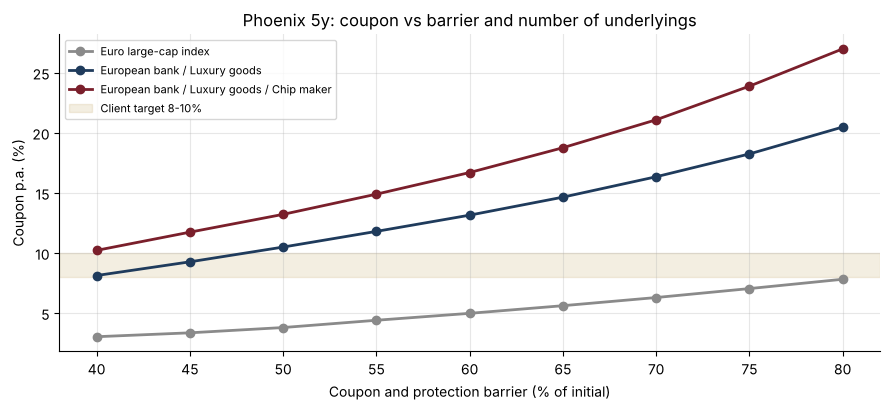

In [4]:
barriers = np.arange(0.40, 0.81, 0.05)
plt.figure(figsize=(9, 4.2))
for names, c in [(("Euro large-cap index",), GREY), (pair.names, NAVY), (pair.names + ("Chip maker",), BORDEAUX)]:
    cps = [solve_coupon(replace(phx, coupon_barrier=b, protection_barrier=b), Market(names=names), n_paths=10_000)["coupon_pa"] for b in barriers]
    plt.plot(barriers * 100, np.array(cps) * 100, marker="o", color=c, lw=2, label=" / ".join(names))
plt.axhspan(8, 10, color=GOLD, alpha=0.15, label="Client target 8-10%")
plt.xlabel("Coupon and protection barrier (% of initial)"); plt.ylabel("Coupon p.a. (%)"); plt.legend(fontsize=8)
plt.title("Phoenix 5y: coupon vs barrier and number of underlyings")
plt.tight_layout(); plt.savefig("images/coupon_grid.png", dpi=150); plt.show()

The coupon rises with every risk the client takes: a higher barrier, more volatility, one more stock
in the worst-of, no memory on missed coupons. The worst-of is the biggest lever: on the index alone
the same structure pays under 5%. Two items are on the bank's side: its **credit spread**, which
funds almost one point of coupon (the client also takes the issuer's credit risk), and the **sales
margin**, where each point of margin costs the client about half a point of coupon a year.

## 3. The client asks: "What barrier gives me 10%?"

In [5]:
b10 = solve_barrier(phx, pair, 0.10)
q10 = solve_coupon(replace(phx, coupon_barrier=b10, protection_barrier=b10), pair)
print(f"Barrier for a 10% coupon: {b10:.1%}  ->  coupon {q10['coupon_pa']:.2%}, "
      f"probability of capital loss {q10['prob_capital_loss']:.0%} (vs {quotes[next(iter(quotes))]['prob_capital_loss']:.0%} at 60%)")

Barrier for a 10% coupon: 47.7%  ->  coupon 9.99%, probability of capital loss 28% (vs 37% at 60%)


Asking for less coupon buys a lower barrier: this is the version to show a client who wants income
but is nervous about the downside.

## 4. When will the note redeem?

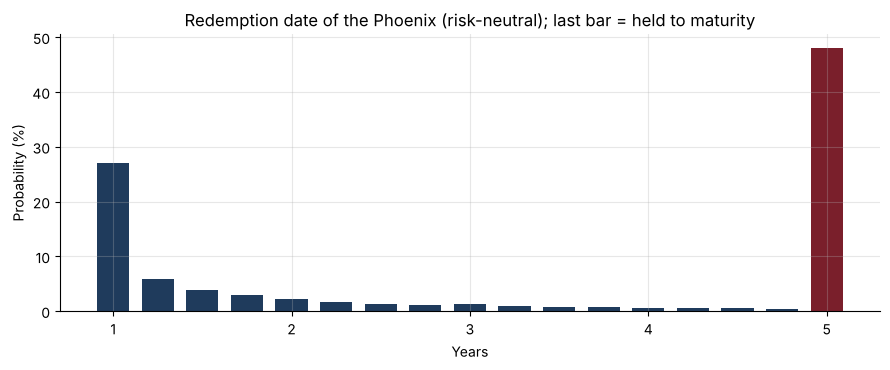

In [6]:
prof = quotes[next(iter(quotes))]["redemption_profile"]
plt.figure(figsize=(9, 3.8))
plt.bar(prof.index, prof.values * 100, width=0.18, color=[NAVY] * (len(prof) - 1) + [BORDEAUX])
plt.xlabel("Years"); plt.ylabel("Probability (%)"); plt.title("Redemption date of the Phoenix (risk-neutral); last bar = held to maturity")
plt.tight_layout(); plt.savefig("images/redemption.png", dpi=150); plt.show()

A large share of notes are called on the first possible date. For the client this is a
**reinvestment risk**: the 13% coupon may last only one year.

## 5. Scenarios for the client

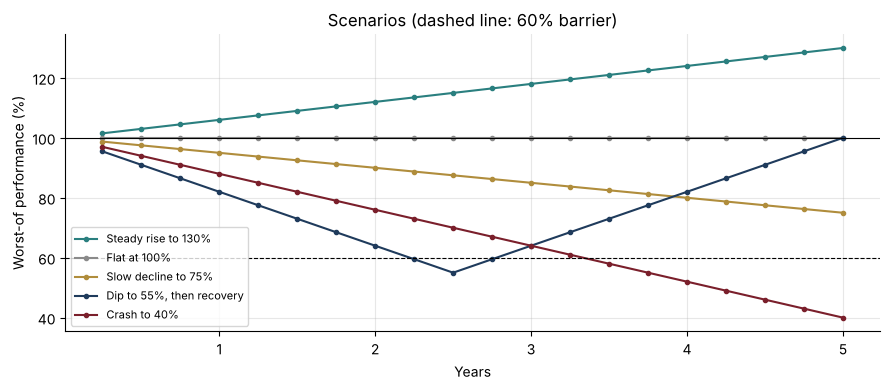

,Redeemed after (years),Coupons received (%),Capital returned (%),Total received (%)
Steady rise to 130%,1.0,13.2,100.0,113.2
Flat at 100%,1.0,13.2,100.0,113.2
Slow decline to 75%,5.0,66.2,100.0,166.2
"Dip to 55%, then recovery",5.0,66.2,100.0,166.2
Crash to 40%,5.0,43.0,40.0,83.0


In [7]:
c = quotes[next(iter(quotes))]["coupon_per_period"]
scen = {"Steady rise to 130%": scenario_path(phx, 1.3), "Flat at 100%": scenario_path(phx, 1.0),
        "Slow decline to 75%": scenario_path(phx, 0.75), "Dip to 55%, then recovery": scenario_path(phx, 0.55, "dip"),
        "Crash to 40%": scenario_path(phx, 0.4)}
scen_table = pd.DataFrame({k: scenario_outcome(phx, c, w) for k, w in scen.items()}).T
fig, ax = plt.subplots(figsize=(9, 4))
for (k, w), col in zip(scen.items(), [TEAL, GREY, GOLD, NAVY, BORDEAUX]):
    ax.plot(phx.times, w * 100, marker=".", color=col, label=k)
for lvl, ls in [(100, "-"), (60, "--")]:
    ax.axhline(lvl, color="black", lw=0.8, ls=ls)
ax.set(xlabel="Years", ylabel="Worst-of performance (%)", title="Scenarios (dashed line: 60% barrier)"); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig("images/scenarios.png", dpi=150); plt.show()
scen_table.round(1)

The table is what the client remembers:
- In a rising or flat market, the note is called after one year with four coupons.
- In a slow decline, she collects every coupon and gets 100% back.
- The dip-and-recovery path shows the **memory** effect: the coupons missed below the barrier are
  paid when the stocks recover.
- Only the crash, a fall below 60% at maturity, costs her capital.

## 6. Indicative term sheet

In [8]:
ts_rows = scen_table.loc[["Steady rise to 130%", "Slow decline to 75%", "Dip to 55%, then recovery", "Crash to 40%"]]
term_sheet_pdf("output/term_sheet_phoenix.pdf", phx, pair, quotes[next(iter(quotes))], ts_rows)
print("Term sheet written to output/term_sheet_phoenix.pdf")

Term sheet written to output/term_sheet_phoenix.pdf


## 7. Live pricer

Run this cell in Colab (badge at the top of the README) to move the sliders and reprice in real
time. On GitHub the sliders are not interactive.

In [9]:
try:
    import ipywidgets as w
    from IPython.display import display

    def quote(maturity=5, barrier=0.60, autocall=1.00, n_stocks=2, vol_shift=0.0, margin=0.015):
        names = ("European bank", "Luxury goods", "Chip maker")[:n_stocks]
        p = Phoenix(maturity=maturity, coupon_barrier=barrier, protection_barrier=barrier, autocall_level=autocall)
        q = solve_coupon(p, Market(names=names, vol_shift=vol_shift), sales_margin=margin, n_paths=10_000)
        display(pd.Series({"Underlyings": " / ".join(names), "Coupon p.a.": f"{q['coupon_pa']:.2%}",
                           "Expected life": f"{q['expected_life']:.1f} years", "Probability of capital loss": f"{q['prob_capital_loss']:.0%}",
                           "Average loss if loss": f"{q['avg_loss_if_loss']:.0f}%"}).to_frame("Indicative quote"))

    w.interact(quote, maturity=w.IntSlider(5, 1, 8, description="Maturity (y)"),
               barrier=w.FloatSlider(0.60, min=0.40, max=0.80, step=0.05, description="Barrier"),
               autocall=w.FloatSlider(1.00, min=0.80, max=1.10, step=0.05, description="Autocall level"),
               n_stocks=w.IntSlider(2, 1, 3, description="Stocks"),
               vol_shift=w.FloatSlider(0.0, min=-0.10, max=0.10, step=0.01, description="Vol shift"),
               margin=w.FloatSlider(0.015, min=0.0, max=0.03, step=0.0025, description="Sales margin", readout_format=".2%"))
except ImportError:
    print("Install ipywidgets (pip install ipywidgets) for the interactive pricer.")

interactive(children=(IntSlider(value=5, description='Maturity (y)', max=8, min=1), FloatSlider(value=0.6, des…

## Conclusions
- One engine prices three product families and solves their coupon or participation exactly
  (tested against a zero-volatility closed form).
- The sensitivity table makes the client conversation concrete: every extra point of coupon is
  paid for with a higher barrier, more volatility, more stocks or the issuer's credit risk.
- Scenario tables and a one-page term sheet turn the numbers into something a client can read.
- **Next steps:** local or stochastic volatility for barrier products, a real issuer funding curve,
  discrete dividends, and an Excel add-in so that salespeople can quote from a spreadsheet.